
**Trabalho Final - Análise de Antenas - 2026/2**

André Fabiano Silva Rios - 2026681087


PARTE 1


$E_{\theta}(\theta,\phi) \propto cos(\theta) cos(\phi)\int_0^{2\pi} \int_0^a\rho'\ ^2 e^{jk\rho'sen(\theta)cos(\phi-\phi')}d\rho'd\phi'
$


$E_{\phi}(\theta,\phi) \propto -sen(\phi)\int_0^{2\pi} \int_0^a\rho' \ ^2 e^{jk\rho'sen(\theta)cos(\phi-\phi')}d\rho'd\phi'
$

Bibliotecas usadas nesta etapa

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

pi = np.pi

Rotina para o cálculo numérico

In [ ]:
num = 51  ### Número de pontos
if num % 2 == 0: num += 1

theta = np.linspace(0,pi,num)
phi = np.linspace(0,pi,num)

a = 1
b = 0

lamb = 100

k = (2*pi)/lamb

f = lambda rho_s,phi_s : rho_s ** 2 * np.exp(1j*k*rho_s*np.sin(theta)*np.cos(phi-phi_s))

### Intervalo de análise
x1 = 0
x2 = a
y1 = 0
y2 = 2*pi

rho_l = np.linspace(x1,x2,num)
phi_l = np.linspace(y1,y2,num)

# eixos para broadcasting: (phi, rho', phi')
PHI  = phi[:, None, None]
RHO  = rho_l[None, :, None]
PHIL = phi_l[None, None, :]

I = np.zeros((num, num), dtype=complex)   # I[theta, phi]

for i, th in enumerate(theta):
    integrando = RHO**2 * np.exp(1j*k*RHO*np.sin(th)*np.cos(PHI - PHIL))
    # integra em phi' (eixo 2) e depois em rho' (eixo 1)
    I[i, :] = simpson(simpson(integrando, x=phi_l, axis=2), x=rho_l, axis=1)

TH, PH = np.meshgrid(theta, phi, indexing='ij')

E_theta =  np.cos(TH)*np.cos(PH)*I
E_phi   = -np.sin(PH)*I

Plot das componentes de campo

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\theta(\theta)$')
ax[1].set_title(r'$E_\theta(\phi)$')

ax[0].plot(theta,np.real(E_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$',color='red')
ax[1].plot(phi,np.real(E_theta[0,:]),label=r'$E_{\theta}(\theta=0,\phi)$')
for i in [0,1]:
    ax[i].set_xticks([ 0, np.pi/4, np.pi/2,3*np.pi/4, np.pi],[r"$0$", r"$\pi/4$", r"$\pi/2$",r"$3\pi/4$",r"$\pi$"])
    ax[i].legend()

ax[0].set_xlabel(r'$\theta$ (rad)')
ax[1].set_xlabel(r'$\phi$ (rad)')
ax[0].set_ylabel('Amplitude')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\phi(\theta)$')
ax[1].set_title(r'$E_\phi(\phi)$')

ax[0].plot(theta,np.real(E_phi[:,int(num/2)]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$',color='red')
ax[1].plot(phi,np.real(E_phi[int(num/2),:]),label=r'$E_{\phi}(\theta=\pi/2,\phi)$')

for i in [0,1]:
    ax[i].set_xticks([ 0, np.pi/4, np.pi/2,3*np.pi/4, np.pi],[r"$0$", r"$\pi/4$", r"$\pi/2$",r"$3\pi/4$",r"$\pi$"])
    ax[i].legend()

ax[0].set_xlabel(r'$\theta$ (rad)')
ax[1].set_xlabel(r'$\phi$ (rad)')
ax[0].set_ylabel('Amplitude')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

im0 = ax[0].imshow(np.real(E_theta),cmap='viridis')
ax[0].set_title(r'$E_\theta(\theta,\phi)$')
fig.colorbar(im0, ax=ax[0], label='Amplitude')

im1 = ax[1].imshow(np.real(E_phi),cmap='viridis')
ax[1].set_title(r'$E_\phi(\theta,\phi)$')
fig.colorbar(im1, ax=ax[1], label='Amplitude')

for i in [0,1]:
    ax[i].set_ylabel(r'$\theta$ (rad)')
    ax[i].set_xlabel(r'$\phi$ (rad)')
    ax[i].set_xticks([ 0, int(num/4), int(num/2),int(3*num/4), num-1],[r"$0$", r"$\pi/4$", r"$\pi/2$",r"$3\pi/4$",r"$\pi$"])
    ax[i].set_yticks([ 0, int(num/4), int(num/2),int(3*num/4), num-1],[r"$0$", r"$\pi/4$", r"$\pi/2$",r"$3\pi/4$",r"$\pi$"])

plt.tight_layout()
plt.show()

Parte 2

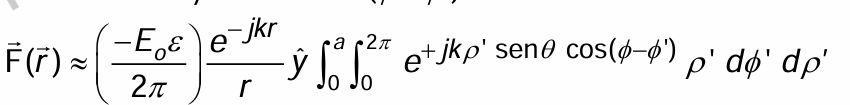

INTEGRAR DE b ATÉ a

y_hat = cos(theta)sen(phi) theta_hat + cos(phi) phi_hat

E(theta,phi) =

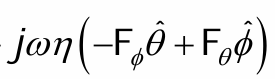

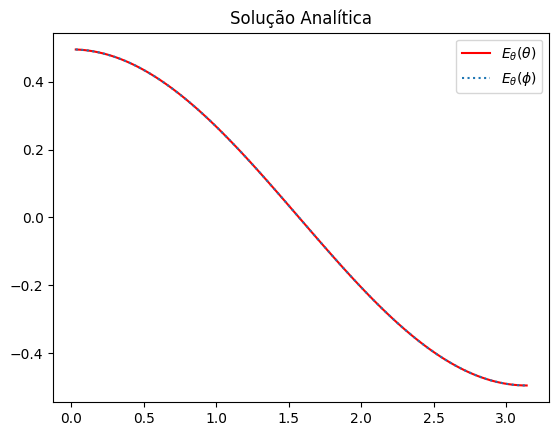

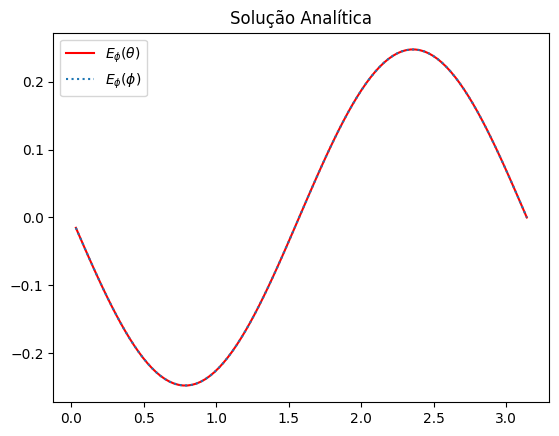

In [17]:
theta = np.linspace(0,pi,num)
phi = np.linspace(0,pi,num)

num = 102  ### Número de pontos
if num % 2 == 0: num += 1

a = 1
b = 0

lamb = 100

k = (2*pi)/lamb

b = a/10

I = a*(jv(1,k*a*np.sin(theta[1:])))/(k*np.sin(theta[1:])) - b*(jv(1,k*b*np.sin(theta[1:])))/(k*np.sin(theta[1:]))

E_theta = np.cos(phi[1:])*I
E_phi = -np.cos(theta[1:])*np.sin(phi[1:])*I

plt.figure()
plt.title('Solução Analítica')
plt.plot(theta[1:],E_theta,label=r'$E_{\theta}(\theta)$',color='red')
plt.plot(phi[1:],E_theta,ls=':',label=r'$E_{\theta}(\phi)$')
plt.legend()
plt.show()

plt.figure()
plt.title('Solução Analítica')
plt.plot(theta[1:],E_phi,label=r'$E_{\phi}(\theta)$',color='red')
plt.plot(phi[1:],E_phi,ls=':',label=r'$E_{\phi}(\phi)$')
plt.legend()
plt.show()

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


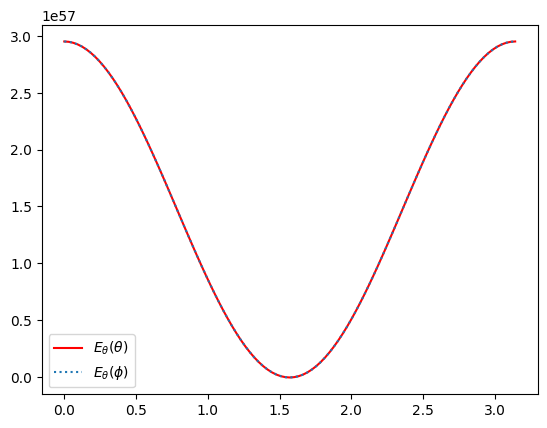

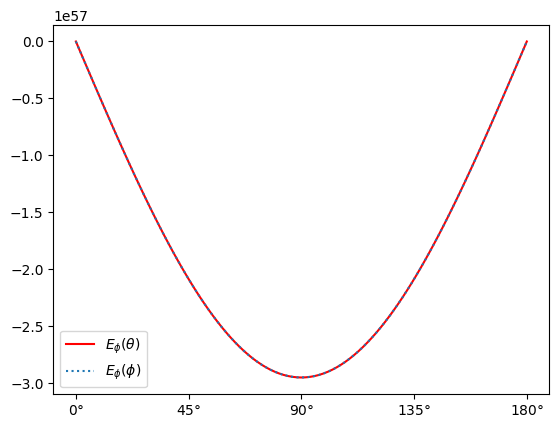

In [18]:
f = lambda rho_s,phi_s : rho_s * np.exp(1j*k*rho_s*np.sin(theta)*np.cos(phi-phi_s))

### Intervalo de análise
x2 = a
x1 = b

y2 = 2*pi
y1 = 0

h = (x2-x1)/(num-1)
I = f(x1,pontos2) + f(x2,pontos2)

for i in range(1,num-1):
    if i % 2 == 0: I += 2*f(pontos[i],pontos2)
    else: I += 4*f(pontos[i],pontos2)

I = (h/3) * I

for i in range(1,num-1):
    if i % 2 == 0: I += 2*I[i]
    else: I += 4*I[i]

h = (y2-y1)/(num-1)
I = (h/3) * I

E_theta = np.zeros((len(theta),len(phi)),dtype=complex)
E_theta = np.cos(theta)*np.cos(phi)*I

E_phi = np.zeros((len(theta),len(phi)),dtype=complex)
E_phi = -np.sin(phi)*I

plt.figure()
plt.plot(theta,E_theta,label=r'$E_{\theta}(\theta)$',color='red')
plt.plot(phi,E_theta,ls=':',label=r'$E_{\theta}(\phi)$')
plt.legend()
plt.show()

plt.figure()
plt.plot(theta,E_phi,label=r'$E_{\phi}(\theta)$',color='red')
plt.plot(phi,E_phi,ls=':',label=r'$E_{\phi}(\phi)$')
plt.xticks([ 0, np.pi/4, np.pi/2,3*np.pi/4, np.pi],[r"$0°$", r"$45°$", r"$90°$",r"$135°$",r"$180°$"])
plt.legend()
plt.show()

Parte 3